# CIFAR-100 classification with Simplex LDA and SIGRegNLL

Companion to `CIFAR100.ipynb`: keep its convolutional encoder, 99-dimensional
embeddings, image transforms, Adam optimizer, batch sizes, and 100-epoch default.
Use **SIGRegNLL** instead of generative NLL: NLL plus class-wise Gaussianity
regularization from [LeJEPA.pdf](LeJEPA.pdf), Section 4.2.3 and Algorithm 1.

Call `SimplexLDAHead(C, D)` with the default fixed covariance $\Sigma=I/D$.
Here $D=99$, so each class targets $N(\mu_c,I_{99}/99)$. SIGReg reads the
variance from the head, keeping its scale aligned with the generative scores.
Train on **all 50,000 training images** and report results on the separate
10,000-image test set. Report test accuracy, predictive NLL and ECE, and plot
confidence and reliability directly from the model's predictions.

Run all cells from `simplex-lda/` or its parent `LDA/`. Requires PyTorch,
torchvision, NumPy, and Matplotlib; the first run may download CIFAR-100.
Set `SIGREG_WEIGHT` in setup; zero recovers generative NLL under the same head.
Figures use `cifar100_sigregnll_*` filenames under `plots/`.


### Setup


In [1]:
from pathlib import Path
import sys

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Support kernels started in simplex-lda/ or its parent LDA/ directory.
project_dir = Path.cwd()
if not (project_dir / 'lda.py').is_file():
    project_dir = project_dir / 'simplex-lda'
if not (project_dir / 'lda.py').is_file():
    raise RuntimeError('Start the kernel in simplex-lda/ or its parent LDA/ directory.')
project_dir = project_dir.resolve()
sys.path.insert(0, str(project_dir))
from lda import SimplexLDAHead
from sigreg import SIGRegNLLLoss

NUM_CLASSES = 100
EMBEDDING_DIM = NUM_CLASSES - 1
EPOCHS = 100
BATCH_SIZE = 256
EVAL_BATCH_SIZE = 1024
NUM_WORKERS = 4  # Set to 0 if multiprocessing is unavailable.
LEARNING_RATE = 1e-3
SIGREG_WEIGHT = 1.0
SIGREG_NUM_SLICES = 256
SIGREG_NUM_POINTS = 65
SIGREG_SEED = 1729

plot_dir = project_dir / 'plots'
plot_dir.mkdir(parents=True, exist_ok=True)


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pin_memory = device.type == 'cuda'
print('device =', device)


device = cuda


### Data

Use the entire official training set with the reference augmentations; test transforms are deterministic.


In [3]:
mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)

train_tfm = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.CIFAR100(root=str(project_dir / 'data'), train=True, transform=train_tfm, download=True)
test_ds = datasets.CIFAR100(root=str(project_dir / 'data'), train=False, transform=test_tfm, download=True)
train_ld = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_ld = DataLoader(
    test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
print(f'Train: {len(train_ds):,}; test: {len(test_ds):,}')


Train: 50,000; test: 10,000


### Model: encoder + LDA head with default fixed covariance $I/D$


In [4]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(256, dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.proj(x)

class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D)  # Default fixed covariance I / D.

    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)


### Train with class-wise SIGRegNLL and evaluate

Use `SIGRegNLLLoss` from `sigreg.py`:
\[
\mathcal L=-\frac1N\sum_i s_{y_i}(z_i)+
\lambda_G\sum_c\frac{n_c}{N}\mathrm{EP}_c,\qquad
s_c(z)=\log\pi_c-\frac12\left(\frac{\|z-\mu_c\|^2}{\sigma^2}
+D\log\sigma^2\right),\quad\sigma^2=1/D.
\]
The NLL term uses the head's **unnormalized generative log scores**, without
applying `log_softmax`. For each class separately, SIGReg compares projected
residuals $(z_i-\mu_c)/\sigma$ against $N(0,1)$, targeting
$N(\mu_c,I_{99}/99)$ in the full embedding space. Centers and variance come
from the head; no empirical centering or whitening is applied.

Use 256 random unit projections, resampled each minibatch with a private seeded
generator, and the paper's Gaussian window on $[-5,5]$. As in
`Synthetic_SIGReg.ipynb`, use a finer **65-point integration grid** to reduce
the translation aliasing of the paper's 17-point grid. Set `SIGREG_NUM_POINTS=17`
to use Algorithm 1's original integration resolution.

Each class retains the paper's $n_c$ multiplier, and classes are weighted by
$n_c/N$. Absent classes and singletons contribute zero, without renormalizing
the other weights. With 100 classes and batch size 256, individual classes have
few examples per batch, making this estimate noisy. The penalty strength also
depends on batch size. `SIGREG_WEIGHT=1.0` is a starting setting, not a tuned
CIFAR-100 result. Finite regularization encourages Gaussianity rather than
guaranteeing it.

As in the reference, Adam optimizes the encoder and class priors. Simplex means
and covariance are fixed. Apply SIGReg from the first epoch and retain the
100-epoch default. Test data reports progress and final metrics; it does not
select epochs or weights.


In [5]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ok = tot = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        ok += (logits.argmax(1) == y).sum().item()
        tot += y.size(0)
    return ok / tot

model = DeepLDA(C=NUM_CLASSES, D=EMBEDDING_DIM).to(device)
variance = model.head.cov_diag[0]
log_variance = variance.log()
opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = SIGRegNLLLoss(
    gaussianity_weight=SIGREG_WEIGHT,
    num_slices=SIGREG_NUM_SLICES,
    seed=SIGREG_SEED,
    num_points=SIGREG_NUM_POINTS,
).to(device)
step = 0

train_acc = []
test_acc = []
train_loss = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum = acc_sum = n_sum = 0
    for x, y in train_ld:
        x, y = x.to(device), y.to(device)
        embeddings = model.encoder(x)
        logits = model.head(embeddings)
        loss = loss_fn(
            logits, y, embeddings, model.head.mu,
            step=step, log_variance=log_variance,
        )
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite SIGRegNLL loss at epoch {epoch}, step {step}')
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        step += 1
        with torch.no_grad():
            pred = logits.argmax(1)
            acc_sum += (pred == y).sum().item()
            n_sum += y.size(0)
            loss_sum += loss.item() * y.size(0)
    tr_acc = acc_sum / n_sum
    te_acc = evaluate(model, test_ld)
    train_loss.append(loss_sum / n_sum)
    train_acc.append(tr_acc)
    test_acc.append(te_acc)
    print(f"[{epoch:02d}] train loss={loss_sum/n_sum:.4f} acc={tr_acc:.4f} | test acc={te_acc:.4f}")


[01] train loss=654.3134 acc=0.0994 | test acc=0.1284
[02] train loss=613.5792 acc=0.1995 | test acc=0.2335
[03] train loss=576.0214 acc=0.2825 | test acc=0.2595
[04] train loss=539.2933 acc=0.3439 | test acc=0.3365
[05] train loss=503.7155 acc=0.3958 | test acc=0.3742
[06] train loss=473.9734 acc=0.4349 | test acc=0.3937
[07] train loss=448.9117 acc=0.4683 | test acc=0.4402
[08] train loss=426.3347 acc=0.4968 | test acc=0.4550
[09] train loss=404.8577 acc=0.5220 | test acc=0.4814
[10] train loss=384.3937 acc=0.5439 | test acc=0.4922
[11] train loss=367.3942 acc=0.5648 | test acc=0.4992
[12] train loss=349.5965 acc=0.5816 | test acc=0.5375
[13] train loss=334.7500 acc=0.5945 | test acc=0.5357
[14] train loss=320.2944 acc=0.6123 | test acc=0.5496
[15] train loss=306.7522 acc=0.6221 | test acc=0.5563
[16] train loss=293.4837 acc=0.6370 | test acc=0.5598
[17] train loss=281.9752 acc=0.6446 | test acc=0.5629
[18] train loss=270.6737 acc=0.6575 | test acc=0.5974
[19] train loss=260.0257 acc

### Test prediction metrics

Compute predictive NLL, ECE, and accuracy directly from the model's test scores.
Predictive NLL uses cross-entropy and is distinct from the generative SIGRegNLL
training objective. Test examples are used only for reporting.


In [6]:
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        logits.append(model(x.to(device)).detach().cpu())
        labels.append(y.cpu())
    return torch.cat(logits), torch.cat(labels)


In [7]:
@torch.no_grad()
def prediction_metrics(logits, labels, n_bins=15):
    confidence, predictions = logits.softmax(dim=1).max(dim=1)
    correct = predictions.eq(labels).float()
    # Equal-width bins, including confidence 0 and 1.
    bin_ids = (confidence * n_bins).long().clamp(max=n_bins - 1)
    ece = confidence.new_zeros(())
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.float().mean() * (
                confidence[mask].mean() - correct[mask].mean()
            ).abs()
    return {
        'NLL': F.cross_entropy(logits, labels).item(),
        'ECE': ece.item(),
        'accuracy': correct.mean().item(),
    }


test_logits, test_labels = collect_logits(model, test_ld)
metrics = prediction_metrics(test_logits, test_labels)
print(f"{'Test predictions':<20} {'NLL':>9} {'ECE':>9} {'Accuracy':>9}")
print(f"{'Original':<20} {metrics['NLL']:9.4f} {metrics['ECE']:9.4f} {metrics['accuracy']:9.4f}")


Test predictions           NLL       ECE  Accuracy
Original              199.2039    0.3512    0.6478


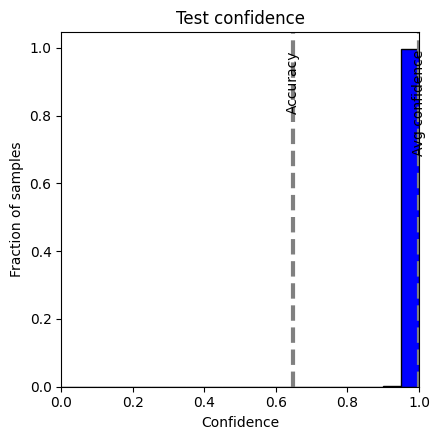

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

plot_dir.mkdir(parents=True, exist_ok=True)
conf_tensor, pred = F.softmax(test_logits, dim=1).max(dim=1)
conf = conf_tensor.detach().cpu().numpy()
pred = pred.cpu()
labels = test_labels.cpu()
acc = (pred == labels).float().mean().item()
avg_conf = conf.mean().item()

bins = np.linspace(0.0, 1.0, 21)
weights = np.ones_like(conf) / conf.size

plt.figure(figsize=(4.5, 4.5))
plt.hist(conf, bins=bins, weights=weights, color='blue', edgecolor='black')
plt.axvline(avg_conf, color='gray', linestyle='--', linewidth=3)
plt.axvline(acc, color='gray', linestyle='--', linewidth=3)
plt.text(avg_conf, 0.95 * plt.gca().get_ylim()[1], 'Avg confidence',
         rotation=90, va='top', ha='center')
plt.text(acc, 0.95 * plt.gca().get_ylim()[1], 'Accuracy',
         rotation=90, va='top', ha='center')
plt.xlabel('Confidence')
plt.ylabel('Fraction of samples')
plt.xlim(0, 1)
plt.title('Test confidence')
plt.tight_layout()
plt.savefig(plot_dir / 'cifar100_sigregnll_confidence_hist.png', dpi=600)

plt.show()


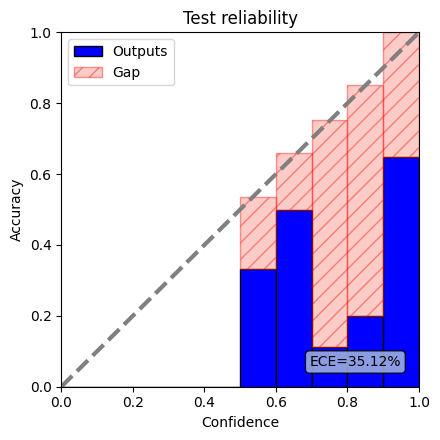

In [9]:
import numpy as np
import matplotlib.pyplot as plt

conf_tensor, pred_tensor = F.softmax(test_logits, dim=1).max(dim=1)
conf = conf_tensor.detach().cpu().numpy()
pred = pred_tensor.detach().cpu().numpy()
labels = test_labels.cpu().numpy()
correct = (pred == labels).astype(np.float32)

n_bins = 10
bins = np.linspace(0.0, 1.0, n_bins + 1)
bin_ids = np.digitize(conf, bins[1:-1], right=True)

bin_acc = np.zeros(n_bins, dtype=np.float32)
bin_conf = np.zeros(n_bins, dtype=np.float32)
bin_frac = np.zeros(n_bins, dtype=np.float32)

for b in range(n_bins):
    mask = bin_ids == b
    if mask.any():
        bin_acc[b] = correct[mask].mean()
        bin_conf[b] = conf[mask].mean()
        bin_frac[b] = mask.mean()

ece = np.sum(np.abs(bin_acc - bin_conf) * bin_frac)

bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=3)
plt.bar(bin_centers, bin_acc, width=bin_width, color='blue', edgecolor='black', label='Outputs')
gap = bin_conf - bin_acc
plt.bar(bin_centers, gap, bottom=bin_acc, width=bin_width, color='salmon', edgecolor='red',
        alpha=0.4, hatch='//', label='Gap')
plt.xlabel('Confidence')
plt.ylabel('Accuracy')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.text(0.95, 0.05, f'ECE={ece*100:.2f}%', ha='right', va='bottom',
         bbox=dict(boxstyle='round', facecolor='lightsteelblue', alpha=0.8))
plt.title('Test reliability')
plt.tight_layout()
plt.savefig(plot_dir / 'cifar100_sigregnll_reliability_diagram.png', dpi=600)

plt.show()
